# Vitaliza · análise de retenção

Notebook que preenche os números do *Plano de Retenção v2*. Segue os 8 objetivos do enunciado, na ordem:

1. Contar e medir a base · 2. Explicar a subida de 2026 · 3. Segmentos · 4. Prever quem sai ·
5. Valor de texto e imagem · 6. Uplift e regra de contato · 7. Retorno em R$ · 8. Mensagem

Data de corte: **30/09/2026**. Todas as datas foram convertidas para horário de Brasília (as lojas gravam em UTC).
As funções de leitura e de variáveis estão em `src/base.py` e `src/features.py`.

In [1]:
import sys, json, warnings
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from base import *
from features import *
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
OUT = "outputs/"; import os; os.makedirs(OUT, exist_ok=True)
R = {}  # resultados que vão para o plano

## 1 · Contar e medir a base

### 1.1 Qualidade dos arquivos
Nenhum arquivo foi limpo antes da entrega. O que foi encontrado e como foi tratado:

In [2]:
e = load_eventos(); a = load_assinaturas(); X = load_all()
u_raw = pd.read_csv(D + "usuarios.csv", dtype=str)
pg_raw = pd.read_csv(D + "pagamentos.csv", dtype=str)
at_raw = X["at"]
q = pd.DataFrame([
    ("eventos_assinatura", "data_hora mistura UTC ('Z', lojas) e BRT (site)", f"{e.data_hora.str.endswith('Z').mean():.0%} em UTC", "convertido para BRT (−3h)"),
    ("pagamentos", "valor em dois formatos ('34.90' e 'R$ 34,90')", f"{pg_raw.valor.str.startswith('R$').mean():.0%} com 'R$'", "convertido para número"),
    ("usuarios", "sexo com 6 grafias (F, Fem, feminino...)", f"{u_raw.sexo.nunique()} valores", "normalizado para F/M"),
    ("usuarios", "sistema com caixa diferente (ios, iOS, IOS)", f"{u_raw.sistema.nunique()} valores", "minúsculas"),
    ("usuarios", "cidade em texto livre (Sampa, SP, S. Paulo...)", f"{u_raw.cidade.nunique()} valores para ~13 cidades", "usar uf e cep_prefixo"),
    ("assinaturas", "60 assinaturas 'cortesia' com canal 'interno'", "60", "excluídas da base pagante"),
    ("assinaturas", "status_atual é retrato de 01/10, não histórico", "—", "status reconstruído pelos eventos"),
    ("atividades", "tipo em português e inglês (run, walk, strength, ride)", f"{X['at'].tipo.nunique()} tipos após unificar", "mapeado para português"),
    ("onboarding", "dias_por_semana em texto ('3x', '3 vezes', 'todos')", "23 grafias", "extraído o número"),
    ("onboarding", "objetivo com respostas vazias ('nada', 'x', 'asdf', emoji)", f"{(X['ob'].objetivo_cat=='vazio').mean():.0%}", "categoria 'vazio'"),
    ("tickets", "categoria do atendente diverge do texto do cliente", "ver 5.1", "tema extraído do texto"),
    ("feed_posts", "posts com erro de digitação e '[post removido]'", "1.214 removidos", "regras sem acento e tolerantes"),
    ("campanha_ago26", "48 sorteados que não aparecem ativos às 10h de 10/08", "48", "mantidos na análise por intenção de tratar"),
], columns=["arquivo", "problema", "tamanho", "tratamento"])
q

,arquivo,problema,tamanho,tratamento
0,eventos_assinatura,"data_hora mistura UTC ('Z', lojas) e BRT (site)",68% em UTC,convertido para BRT (−3h)
1,pagamentos,"valor em dois formatos ('34.90' e 'R$ 34,90')",12% com 'R$',convertido para número
2,usuarios,"sexo com 6 grafias (F, Fem, feminino...)",6 valores,normalizado para F/M
3,usuarios,"sistema com caixa diferente (ios, iOS, IOS)",5 valores,minúsculas
4,usuarios,"cidade em texto livre (Sampa, SP, S. Paulo...)",36 valores para ~13 cidades,usar uf e cep_prefixo
5,assinaturas,60 assinaturas 'cortesia' com canal 'interno',60,excluídas da base pagante
6,assinaturas,"status_atual é retrato de 01/10, não histórico",—,status reconstruído pelos eventos
7,atividades,"tipo em português e inglês (run, walk, strengt...",7 tipos após unificar,mapeado para português
8,onboarding,"dias_por_semana em texto ('3x', '3 vezes', 'to...",23 grafias,extraído o número
9,onboarding,"objetivo com respostas vazias ('nada', 'x', 'a...",30%,categoria 'vazio'


### 1.2 Reconstrução do status a partir dos eventos
`assinaturas.csv` sobrescreve o status a cada mudança. O status numa data passada sai de `eventos_assinatura.csv`:
um período pagante começa em `assinatura_iniciada` (ou já existe em 01/07/2024 para assinaturas mais antigas) e termina em
`assinatura_expirada` ou `reembolso`. Quem desligou a renovação continua ativo até expirar.

A regra reproduz exatamente os números do enunciado:

In [3]:
sp = spells(e, a)
ch = churn_mensal(sp, pd.date_range("2025-01-01", "2026-09-01", freq="MS"))
check = pd.DataFrame({
    "enunciado": [14753, 8540, 14237, 1154, 14319, "5,6%", "6,6%"],
    "reconstruído": [len(ativos_em(sp, CORTE)), ch.ativos_inicio[0], ch.set_index("mes").loc["2026-04", "ativos_inicio"],
                     ch.set_index("mes").loc["2026-04", "perdas"], ch.set_index("mes").loc["2026-09", "ativos_inicio"],
                     f"{ch[ch.mes < '2026'].churn.mean():.1%}", f"{ch[ch.mes >= '2026'].churn.mean():.1%}"],
}, index=["ativos 30/09/26", "ativos início jan/25", "ativos início abr/26", "perdas abr/26", "ativos início set/26", "churn médio 2025", "churn médio jan–set/26"])
check

,enunciado,reconstruído
ativos 30/09/26,14753,14753
ativos início jan/25,8540,8540
ativos início abr/26,14237,14237
perdas abr/26,1154,1154
ativos início set/26,14319,14319
churn médio 2025,"5,6%",5.6%
churn médio jan–set/26,"6,6%",6.6%


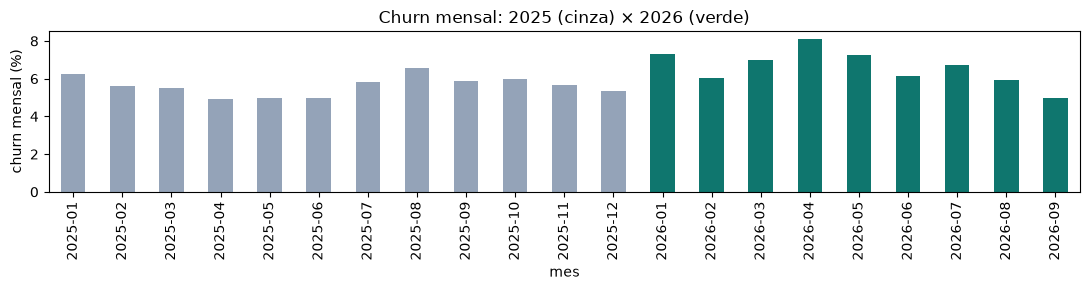

In [4]:
ax = ch.set_index("mes").churn.mul(100).plot(kind="bar", figsize=(11, 3), color=["#94a3b8"] * 12 + ["#0f766e"] * 9)
ax.set_ylabel("churn mensal (%)"); ax.set_title("Churn mensal: 2025 (cinza) × 2026 (verde)"); plt.tight_layout()
ch.to_csv(OUT + "churn_mensal.csv", index=False)

### 1.3 Mix da base no corte e churn por plano × canal

In [5]:
at_c = ativos_em(sp, CORTE)
mix = pd.concat([at_c.plano.value_counts(normalize=True), at_c.canal.value_counts(normalize=True)]).round(3)
print(mix.to_string())

def churn_por(sp, col, meses):
    out = []
    for m in meses:
        t0 = pd.Timestamp(m); t1 = t0 + pd.offsets.MonthBegin(1)
        at = ativos_em(sp, t0)
        lost = at.fim.notna() & (at.fim < t1)
        out.append(at.assign(lost=lost, ano=t0.year).groupby(["ano", col]).lost.agg(["sum", "size"]))
    s = pd.concat(out).groupby(level=[0, 1]).sum()
    return (s["sum"] / s["size"]).unstack(0)

meses25 = pd.date_range("2025-01-01", "2025-12-01", freq="MS"); meses26 = pd.date_range("2026-01-01", "2026-09-01", freq="MS")
pc = churn_por(sp.assign(pc=sp.plano + " · " + sp.canal), "pc", list(meses25) + list(meses26))
pc["Δ pp"] = (pc[2026] - pc[2025]) * 100
R["churn_plano_canal"] = pc.round(4).reset_index().to_dict("records")
pc.style.format({2025: "{:.1%}", 2026: "{:.1%}", "Δ pp": "{:+.1f}"})

anual          0.575
mensal         0.425
app_store      0.366
google_play    0.336
web_cartao     0.203
web_pix        0.095


ano,2025,2026,Δ pp
pc,,,
anual · app_store,2.6%,3.1%,+0.5
anual · google_play,2.7%,3.4%,+0.6
anual · web_cartao,2.9%,3.6%,+0.7
anual · web_pix,2.8%,3.2%,+0.4
mensal · app_store,8.6%,9.6%,+1.0
mensal · google_play,8.4%,11.3%,+2.9
mensal · web_cartao,10.2%,12.4%,+2.2
mensal · web_pix,9.1%,10.9%,+1.8


### 1.4 Voluntário × involuntário
Perda involuntária = expirou depois de `periodo_carencia` (cobrança recusada).

In [6]:
car = e[e.evento == "periodo_carencia"][["user_id", "ts"]].rename(columns={"ts": "ts_car"})
fins = sp[sp.fim.notna()].merge(car, on="user_id", how="left")
fins["invol"] = fins.ts_car.between(fins.ini, fins.fim)
inv = fins.groupby(["user_id", "fim"]).invol.any().reset_index()
inv["mes"] = inv.fim.dt.strftime("%Y-%m")
iv = inv.groupby("mes").invol.sum().reindex(ch.mes).fillna(0)
ch["involuntario_pp"] = (iv.values / ch.ativos_inicio * 100)
ch["voluntario_pp"] = ch.churn * 100 - ch.involuntario_pp
R["invol_pp_2025"] = ch[ch.mes < "2026"].involuntario_pp.mean(); R["invol_pp_2026"] = ch[ch.mes >= "2026"].involuntario_pp.mean()
ch[["mes", "churn", "involuntario_pp", "voluntario_pp"]].round(3).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
mes,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
churn,0.063,0.056,0.055,0.049,0.05,0.05,0.058,0.066,0.059,0.06,0.057,0.053,0.073,0.06,0.07,0.081,0.073,0.061,0.067,0.059,0.05
involuntario_pp,0.386,0.467,0.449,0.359,0.43,0.38,0.524,0.491,0.324,0.491,0.438,0.468,0.441,0.422,0.553,0.499,0.453,0.411,0.405,0.42,0.503
voluntario_pp,5.867,5.15,5.063,4.576,4.535,4.586,5.309,6.062,5.532,5.486,5.223,4.868,6.857,5.624,6.456,7.607,6.814,5.73,6.338,5.523,4.484


## 2 · Explicar a subida de 2026

Hipóteses testadas: (a) renovações anuais concentradas em janeiro, (b) reajuste do mensal em 01/03, (c) falha de GPS no Android,
(d) falha de pagamento, (e) mudança de perfil da base, (f) a pesquisa de saída. Cruzamento aponta suspeitos, não prova causa.

### 2a · Composição: anuais chegando à renovação

In [7]:
cp = None
def churn_plano(meses):
    out = []
    for m in meses:
        t0 = pd.Timestamp(m); t1 = t0 + pd.offsets.MonthBegin(1); at = ativos_em(sp, t0)
        out.append(at.assign(lost=at.fim.notna() & (at.fim < t1), mes=t0.strftime("%Y-%m")).groupby(["mes", "plano"]).lost.agg(["mean", "size"]))
    return pd.concat(out).unstack()
cpx = churn_plano(pd.date_range("2025-01-01", "2026-09-01", freq="MS"))
cp = cpx["mean"]; share = cpx["size"].div(cpx["size"].sum(1), axis=0)
# anuais vencem no aniversário da assinatura
ani = a.sort_values("inicio").groupby("user_id").inicio.last()
rows = []
for ano in (2025, 2026):
    t0 = pd.Timestamp(f"{ano}-01-01"); t1 = pd.Timestamp(f"{ano}-02-01")
    an = ativos_em(sp, t0); an = an[an.plano == "anual"]
    vence = an.user_id.map(ani).dt.month.eq(1) & an.user_id.map(ani).lt(t0 - pd.Timedelta(days=300))
    lost = an.fim.notna() & (an.fim < t1 + pd.Timedelta(days=3))
    rows.append((ano, len(an), int(vence.sum()), lost[vence].mean(), int(lost.sum())))
jj = pd.DataFrame(rows, columns=["ano", "anuais ativos 1/jan", "vencem em jan", "% saem entre os que vencem", "perdas anuais em jan"]).set_index("ano")
R["jan"] = jj.reset_index().to_dict("records")
display(jj)
# decomposição da subida: 2025 × jan–set/2026
p25, p26 = slice("2025-01", "2025-12"), slice("2026-01", "2026-09")
c25, c26, s25, s26 = cp.loc[p25].mean(), cp.loc[p26].mean(), share.loc[p25].mean(), share.loc[p26].mean()
dec = pd.DataFrame({"2025": [s25["anual"], c25["anual"], s25["mensal"], c25["mensal"]],
                    "jan–set/26": [s26["anual"], c26["anual"], s26["mensal"], c26["mensal"]]},
                   index=["% anual na base", "churn anual", "% mensal na base", "churn mensal"])
contrib = pd.Series({
    "anuais saindo mais (renovações maduras)": s25["anual"] * (c26["anual"] - c25["anual"]) * 100,
    "mensais saindo mais (preço, GPS)": s25["mensal"] * (c26["mensal"] - c25["mensal"]) * 100,
    "mudança de mix (mais anuais, que saem menos)": ((s26 - s25) * c26).sum() * 100,
})
R["decomp"] = contrib.round(2).to_dict(); R["churn_plano_ano"] = dec.round(4).to_dict()
print("Contribuição para a subida (pp):"); print(contrib.round(2).to_string()); print("total:", round(contrib.sum(), 2))
dec.round(3)

,anuais ativos 1/jan,vencem em jan,% saem entre os que vencem,perdas anuais em jan
ano,,,,
2025,4358,224,0.366071,97
2026,7125,670,0.441791,339


Contribuição para a subida (pp):
anuais saindo mais (renovações maduras)         0.37
mensais saindo mais (preço, GPS)                0.87
mudança de mix (mais anuais, que saem menos)   -0.25
total: 0.99


,2025,jan–set/26
% anual na base,0.531,0.563
churn anual,0.026,0.033
% mensal na base,0.469,0.437
churn mensal,0.090,0.108


### 2b · Reajuste do mensal (01/03/2026): diferença em diferenças, mensal × anual

mensal: 8.9% → 13.0% | anual: 3.6% → 3.0%
Diferença em diferenças (mar–mai × set–fev): +4.7 pp por mês no mensal


mes,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
plano,,,,,,,,,,,,,,,,,,,,,
anual,0.0202,0.0192,0.0177,0.0152,0.0173,0.0184,0.0307,0.0363,0.0392,0.0386,0.0316,0.0312,0.0414,0.0342,0.0347,0.0284,0.0270,0.0245,0.0325,0.0366,0.0399
mensal,0.1066,0.0946,0.0946,0.0866,0.0858,0.0853,0.0905,0.1003,0.0819,0.0848,0.0859,0.0795,0.1104,0.0914,0.1117,0.1449,0.1319,0.1114,0.1165,0.0924,0.0639


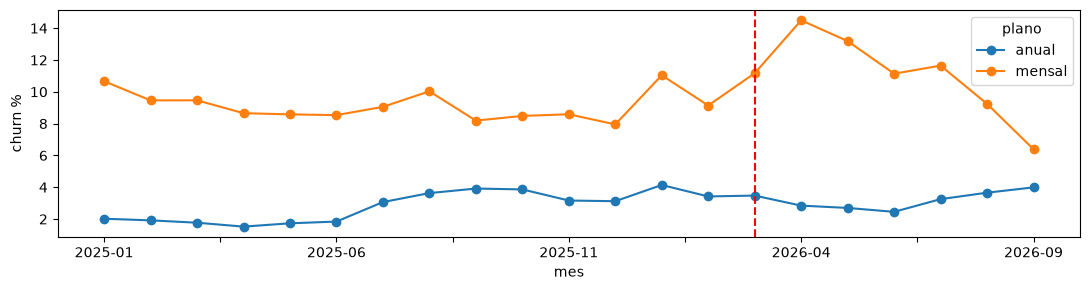

In [8]:
pre = cp.loc["2025-09":"2026-02"].mean(); pos = cp.loc["2026-03":"2026-05"].mean()
did = ((pos["mensal"] - pre["mensal"]) - (pos["anual"] - pre["anual"])) * 100
R["did_preco_pp_mes"] = did
print(f"mensal: {pre['mensal']:.1%} → {pos['mensal']:.1%} | anual: {pre['anual']:.1%} → {pos['anual']:.1%}")
print(f"Diferença em diferenças (mar–mai × set–fev): {did:+.1f} pp por mês no mensal")
ax = cp.mul(100).plot(figsize=(11, 3), marker="o"); ax.axvline(cp.index.get_loc("2026-03"), color="red", ls="--"); ax.set_ylabel("churn %"); plt.tight_layout()
cp.round(4).T

Mesma comparação, só entre os mensais: quem já pagou R$ 39,90 × quem ainda tinha a última cobrança a R$ 34,90.

In [9]:
pg = X["pg"]
mens = pg[(pg.status == "aprovado") & pg.valor.isin([34.90, 39.90])]
first_new = mens[mens.valor == 39.90].groupby("user_id").ts.min()
at_mar = ativos_em(sp, "2026-03-01"); m = at_mar[at_mar.plano == "mensal"].copy()
m["saiu_90d"] = m.fim.notna() & (m.fim < pd.Timestamp("2026-05-30"))
m["viu_preco_novo"] = m.user_id.map(first_new).lt(pd.Timestamp("2026-05-30"))
at_25 = ativos_em(sp, "2025-03-01"); m25 = at_25[at_25.plano == "mensal"]
base25 = (m25.fim.notna() & (m25.fim < pd.Timestamp("2025-05-30"))).mean()
R["mensal_saida_90d_2025"] = base25; R["mensal_saida_90d_2026"] = m.saiu_90d.mean()
print(f"mensais ativos em 1/mar: saem em 90 dias → 2025: {base25:.1%} | 2026: {m.saiu_90d.mean():.1%}  (Δ {(m.saiu_90d.mean()-base25)*100:+.1f} pp)")

mensais ativos em 1/mar: saem em 90 dias → 2025: 24.5% | 2026: 33.3%  (Δ +8.8 pp)


### 2c · GPS no Android (jun–jul)

In [10]:
u = X["u"].set_index("user_id")
def churn_sis(meses):
    out = []
    for mm in meses:
        t0 = pd.Timestamp(mm); t1 = t0 + pd.offsets.MonthBegin(1); at = ativos_em(sp, t0).copy()
        at["sis"] = at.user_id.map(u.sistema)
        out.append(at.assign(lost=at.fim.notna() & (at.fim < t1), mes=t0.strftime("%Y-%m")).groupby(["mes", "sis"]).lost.mean())
    return pd.concat(out).unstack()
cs = churn_sis(pd.date_range("2026-01-01", "2026-09-01", freq="MS"))
cs["Δ android−ios (pp)"] = (cs.android - cs.ios) * 100
atv = X["at"].copy(); atv["mes"] = atv.inicio.dt.strftime("%Y-%m"); atv["sis"] = atv.user_id.map(u.sistema)
gf = atv[atv.tipo.isin(["corrida", "caminhada", "pedal"])].groupby(["mes", "sis"]).gps_ok.apply(lambda s: 1 - s.mean()).unstack()
tk = X["tk"].copy(); tk["mes"] = tk.ts.dt.strftime("%Y-%m")
tgps = tk[tk.tema == "gps"].groupby("mes").size()
out = cs.join(gf.add_prefix("falha_gps_"), how="left").join(tgps.rename("tickets_gps"))
R["android_gap_junjul_pp"] = out.loc["2026-06":"2026-07", "Δ android−ios (pp)"].mean()
R["android_gap_janmai_pp"] = out.loc["2026-01":"2026-05", "Δ android−ios (pp)"].mean()
tg = tk[tk.tema == "gps"].groupby("mes").size().reindex(sorted(tk.mes.unique()), fill_value=0)
R["tickets_gps"] = tg.to_dict()
print("Chamados de GPS por mês (pelo texto do cliente):", tg[tg > 0].to_dict(), "| demais meses: 0")
out.round(3)

Chamados de GPS por mês (pelo texto do cliente): {'2026-05': 535, '2026-06': 418} | demais meses: 0


,android,ios,Δ android−ios (pp),falha_gps_android,falha_gps_ios,tickets_gps
mes,,,,,,
2026-01,0.076,0.070,0.533,0.000,0.0,NaN
2026-02,0.063,0.057,0.564,0.000,0.0,NaN
2026-03,0.070,0.070,0.084,0.000,0.0,NaN
2026-04,0.082,0.080,0.236,0.000,0.0,NaN
2026-05,0.073,0.072,0.113,0.192,0.0,535.0
2026-06,0.073,0.049,2.441,0.195,0.0,418.0
2026-07,0.079,0.055,2.339,0.000,0.0,NaN
2026-08,0.059,0.060,-0.057,0.000,0.0,NaN
2026-09,0.051,0.048,0.273,0.000,0.0,NaN


### 2d–f · Falha de pagamento, perfil da base e pesquisa de saída

In [11]:
mixq = []
for t in ["2025-06-01", "2026-06-01"]:
    at = ativos_em(sp, t).copy(); at["aq"] = at.user_id.map(u.canal_aquisicao); at["sis"] = at.user_id.map(u.sistema)
    mixq.append(pd.concat([at.plano.value_counts(normalize=True), at.canal.value_counts(normalize=True), at.aq.value_counts(normalize=True), at.sis.value_counts(normalize=True)]).rename(t[:7]))
print("Involuntário médio: 2025 = %.2f pp | 2026 = %.2f pp" % (R["invol_pp_2025"], R["invol_pp_2026"]))
display(pd.concat(mixq, axis=1).round(3))
ps = pd.read_csv(D + "pesquisa_saida.csv", dtype=str)
print("Pesquisa de saída: motivos declarados (só site, ~10% das saídas):")
ps.motivo_principal.value_counts(normalize=True).round(3)

Involuntário médio: 2025 = 0.43 pp | 2026 = 0.46 pp


,2025-06,2026-06
anual,0.533,0.575
mensal,0.467,0.425
google_play,0.343,0.343
app_store,0.339,0.356
web_cartao,0.218,0.203
web_pix,0.100,0.099
organico,0.326,0.326
meta_ads,0.183,0.172
indicacao,0.152,0.152
influenciador,0.121,0.141


Pesquisa de saída: motivos declarados (só site, ~10% das saídas):


motivo_principal
preco               0.411
outro               0.347
nao_uso             0.126
outro_app           0.053
problema_tecnico    0.042
saude               0.022
Name: proportion, dtype: float64

## 3 · Segmentos (k-means)

Variáveis de comportamento no corte, padronizadas e com log nas assimétricas. A saída **não** entra.
O risco observado por segmento vem do snapshot de 31/07 (saída nos 60 dias seguintes) só para leitura.

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
SEG_VARS = ["dias_ativos_m1", "dias_ativos_m2", "sessoes_app_m1", "treinos_90d", "tend_dias", "seguidores", "seguindo",
            "treino_junto_90d", "tempo_casa_d", "mensal", "renov_desligada", "ar_livre_share"]
def seg_matrix(f):
    M = f[SEG_VARS].copy().fillna(0)
    for c in ["sessoes_app_m1", "treinos_90d", "seguidores", "seguindo", "treino_junto_90d", "tempo_casa_d"]:
        M[c] = np.log1p(M[c].clip(lower=0))
    return M
f_cut = snapshot(CORTE, sp, e, a, X)
f_jul = snapshot("2026-07-31", sp, e, a, X)
sc = StandardScaler().fit(seg_matrix(f_cut))
Z = sc.transform(seg_matrix(f_cut))
sil = {k: silhouette_score(Z, KMeans(k, n_init=10, random_state=0).fit_predict(Z), sample_size=5000, random_state=0) for k in range(3, 9)}
print("silhueta por k:", {k: round(v, 3) for k, v in sil.items()})

silhueta por k: {3: 0.197, 4: 0.189, 5: 0.172, 6: 0.176, 7: 0.189, 8: 0.177}


In [13]:
K = 6
km = KMeans(K, n_init=20, random_state=0).fit(Z)
f_cut["seg"] = km.labels_
f_jul["seg"] = km.predict(sc.transform(seg_matrix(f_jul)))
prof = f_cut.groupby("seg")[SEG_VARS].mean()
prof["n"] = f_cut.seg.value_counts(); prof["% base"] = prof.n / len(f_cut)
prof["saída 60d (jul)"] = f_jul.groupby("seg").y.mean()
prof.round(2)

,dias_ativos_m1,dias_ativos_m2,sessoes_app_m1,treinos_90d,tend_dias,seguidores,seguindo,treino_junto_90d,tempo_casa_d,mensal,renov_desligada,ar_livre_share,n,% base,saída 60d (jul)
seg,,,,,,,,,,,,,,,
0,7.33,7.06,12.00,34.53,1.10,2.44,2.40,4.71,536.43,0.52,0.03,0.53,738,0.05,0.07
1,3.89,4.47,6.25,28.04,-0.45,0.55,0.54,0.01,403.88,0.47,0.02,0.52,2494,0.17,0.08
2,3.89,4.38,6.20,27.83,-0.46,2.79,2.80,0.03,534.92,0.50,0.01,0.52,3776,0.26,0.07
3,12.48,11.76,20.73,43.54,3.23,1.72,1.72,0.02,447.88,0.49,0.01,0.53,3116,0.21,0.05
4,5.69,1.73,9.44,13.45,5.50,0.20,0.27,0.09,28.78,0.65,0.02,0.55,1907,0.13,0.11
5,0.39,0.70,1.57,3.96,-0.74,1.84,1.86,0.02,480.14,0.02,0.75,0.46,2722,0.18,0.22


Nomes dados aos segmentos a partir do perfil (rodar a célula acima e conferir se a ordem mudou):

In [14]:
pm = seg_matrix(f_cut).groupby(f_cut.seg).mean()
names, livres = {}, set(range(K))
def pega(nome, s):
    names[s] = nome; livres.discard(s)
pega("Renovação desligada", pm.renov_desligada.idxmax())
pega("Recém-chegados", pm.loc[list(livres)].tempo_casa_d.idxmin())
pega("Treinam em grupo", pm.loc[list(livres)].treino_junto_90d.idxmax())
pega("Assíduos", pm.loc[list(livres)].dias_ativos_m1.idxmax())
rest = pm.loc[list(livres)].seguidores.sort_values()
for k, s_ in enumerate(rest.index):
    pega(["Moderados sem rede", "Moderados conectados", "Moderados"][min(k, 2)] if len(rest) <= 3 else f"Moderados {k+1}", s_)
f_cut["segmento"] = f_cut.seg.map(names); f_jul["segmento"] = f_jul.seg.map(names)
seg_tab = pd.DataFrame({
    "n": f_cut.segmento.value_counts(),
    "% mensal": f_cut.groupby("segmento").mensal.mean(),
    "dias ativos/mês": f_cut.groupby("segmento").dias_ativos_m1.mean(),
    "seguidores": f_cut.groupby("segmento").seguidores.mean(),
    "tempo de casa (d)": f_cut.groupby("segmento").tempo_casa_d.mean(),
    "saída 60d observada (ref. 31/07)": f_jul.groupby("segmento").y.mean(),
}).sort_values("saída 60d observada (ref. 31/07)", ascending=False)
R["segmentos"] = seg_tab.round(3).reset_index().rename(columns={"index": "segmento"}).to_dict("records")
seg_tab.round(3)

,n,% mensal,dias ativos/mês,seguidores,tempo de casa (d),saída 60d observada (ref. 31/07)
segmento,,,,,,
Renovação desligada,2722,0.016,0.389,1.843,480.143,0.225
Recém-chegados,1907,0.650,5.690,0.196,28.775,0.114
Moderados sem rede,2494,0.469,3.887,0.555,403.884,0.082
Moderados conectados,3776,0.502,3.892,2.791,534.917,0.070
Treinam em grupo,738,0.522,7.331,2.444,536.432,0.068
Assíduos,3116,0.495,12.483,1.723,447.879,0.055


## 4 · Prever quem sai em 60 dias

* **Treino:** snapshots de 01/03, 01/04, 01/05 e 01/06/2026 (rótulos até 31/07).
* **Teste fora do tempo:** snapshot de 31/07/2026 (rótulo até 29/09). Nada do teste é visto no treino.
* **Escoragem final:** 30/09/2026 → saída até 29/11/2026.
* Variáveis só com dados anteriores à data. `status_atual`, `data_fim` e `motivo_fim` ficam fora.
* A campanha de 10/08 cai na janela do teste; os grupos são sorteados, então o efeito se dilui igualmente.

In [15]:
TRAIN_REFS = ["2026-03-01", "2026-04-01", "2026-05-01", "2026-06-01"]
TEST_REF = "2026-07-31"
def build(ref):
    f = snapshot(ref, sp, e, a, X)
    return f.join(text_features(ref, f, X))
tr = pd.concat([build(r).assign(ref=r) for r in TRAIN_REFS])
te = build(TEST_REF)
fc = build(CORTE)
BASE = ["mensal", "loja", "renov_desligada", "dias_desde_desligou", "dias_ate_cobranca", "cobranca_na_janela", "carencia_60d",
        "tempo_casa_d", "mensal_preco_novo", "recusas_90d", "pagou_cupom",
        "dias_ativos_m1", "dias_ativos_m2", "dias_ativos_m3", "sessoes_app_m1", "sessoes_app_m2", "minutos_m1", "tend_dias",
        "treinos_30d", "treinos_90d", "dias_desde_treino", "gps_falha_90d", "treino_junto_90d", "ar_livre_share",
        "android", "relogio", "idade", "mulher", "seguidores", "seguindo",
        "aq_influenciador", "aq_meta_ads", "aq_indicacao", "aq_google_ads", "aq_parceria_corporativa"]
TEXT = [c for c in te.columns if c.startswith(("post_", "ticket_", "obj_"))] + ["posts_60d", "dias_meta"]
print(f"treino: {len(tr):,} linhas, saída {tr.y.mean():.1%} | teste: {len(te):,}, saída {te.y.mean():.1%} | corte: {len(fc):,}")

treino: 56,569 linhas, saída 13.4% | teste: 14,049, saída 10.6% | corte: 14,753


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score
import lightgbm as lgb

MODELS = {
    "Regressão logística": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.5, max_iter=2000)),
    "Árvore de decisão": lambda: make_pipeline(SimpleImputer(strategy="median"), DecisionTreeClassifier(max_depth=5, min_samples_leaf=200, random_state=0)),
    "Random forest (bagging)": lambda: make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(400, min_samples_leaf=30, n_jobs=-1, random_state=0)),
    "Gradient boosting": lambda: lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0),
}
TOPN = 1500
def capture(y, p, n=TOPN):
    n = int(round(n * len(y) / 14753))  # mesmo tamanho relativo da lista do CRM
    idx = np.argsort(-p)[:n]
    return y.values[idx].sum() / y.sum()

def avaliar(cols):
    res, preds = [], {}
    for nome, mk in MODELS.items():
        m = mk().fit(tr[cols], tr.y)
        p = m.predict_proba(te[cols])[:, 1]
        preds[nome] = (m, p)
        res.append((nome, roc_auc_score(te.y, p), average_precision_score(te.y, p), capture(te.y, p)))
    return pd.DataFrame(res, columns=["modelo", "AUC", "PR-AUC", "captura top 1.500"]).set_index("modelo"), preds

res_base, pred_base = avaliar(BASE)
res_text, pred_text = avaliar(BASE + TEXT)
cmp = res_base.join(res_text, rsuffix=" (+texto)")
cmp["captura ao acaso"] = TOPN / 14753
lig = (te.renov_desligada == 0).values
cmp["AUC só renovação ligada (+texto)"] = [roc_auc_score(te.y[lig], pred_text[m][1][lig]) for m in cmp.index]
R["modelos"] = cmp.round(3).reset_index().to_dict("records")
cmp.round(3)

,AUC,PR-AUC,captura top 1.500,AUC (+texto),PR-AUC (+texto),captura top 1.500 (+texto),captura ao acaso,AUC só renovação ligada (+texto)
modelo,,,,,,,,
Regressão logística,0.919,0.725,0.610,0.932,0.756,0.653,0.102,0.846
Árvore de decisão,0.917,0.680,0.593,0.917,0.691,0.630,0.102,0.809
Random forest (bagging),0.925,0.740,0.629,0.936,0.769,0.665,0.102,0.854
Gradient boosting,0.923,0.736,0.626,0.935,0.765,0.661,0.102,0.852


Regras da árvore (leitura de negócio) e importância das variáveis do melhor modelo:

In [17]:
tree = pred_text["Árvore de decisão"][0][-1]
print(export_text(tree, feature_names=BASE + TEXT, max_depth=3))
gb = pred_text["Gradient boosting"][0]
imp = pd.Series(gb.booster_.feature_importance("gain"), index=BASE + TEXT).sort_values(ascending=False)
R["top_vars"] = imp.head(10).index.tolist()
(imp / imp.sum()).head(15).round(3)

|--- dias_ate_cobranca <= 59.50
|   |--- dias_desde_desligou <= -0.50
|   |   |--- post_meta_cumprida <= 0.50
|   |   |   |--- post_lesao <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- post_lesao >  0.50
|   |   |   |   |--- class: 1
|   |   |--- post_meta_cumprida >  0.50
|   |   |   |--- tempo_casa_d <= 169.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- tempo_casa_d >  169.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- dias_desde_desligou >  -0.50
|   |   |--- dias_ate_cobranca <= 21.50
|   |   |   |--- dias_ate_cobranca <= 16.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- dias_ate_cobranca >  16.50
|   |   |   |   |--- class: 1
|   |   |--- dias_ate_cobranca >  21.50
|   |   |   |--- mulher <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- mulher >  0.50
|   |   |   |   |--- truncated branch of depth 2
|--- dias_ate_cobranca >  59.50
|   |--- dias_ate_cobranca <= 353.50
|   |

dias_ate_cobranca      0.393
renov_desligada        0.243
tempo_casa_d           0.045
cobranca_na_janela     0.033
dias_desde_desligou    0.030
dias_desde_treino      0.024
idade                  0.024
post_meta_cumprida     0.023
ar_livre_share         0.019
mensal                 0.013
treinos_90d            0.012
minutos_m1             0.012
sessoes_app_m2         0.011
treinos_30d            0.011
post_lesao             0.008
dtype: float64

Calibração por decil (a probabilidade entra na conta de retorno):

In [18]:
p_te = pred_text["Gradient boosting"][1]
cal = pd.DataFrame({"p": p_te, "y": te.y.values}).assign(decil=lambda d: pd.qcut(d.p, 10, labels=False)).groupby("decil").agg(prevista=("p", "mean"), observada=("y", "mean"))
cal.round(3).T

decil,0,1,2,3,4,5,6,7,8,9
prevista,0.0,0.0,0.0,0.0,0.003,0.055,0.098,0.152,0.256,0.773
observada,0.0,0.0,0.0,0.0,0.006,0.048,0.050,0.107,0.152,0.692


## 5 · Valor de texto e imagem

### 5.1 Extração de texto
Os textos são curtos e muito repetidos: há poucos milhares de frases distintas. A extração é feita **uma vez por frase distinta**
(regras em `src/features.py`, com o mesmo esquema de saída que o prompt do LLM devolve) e reaproveitada para todos que escreveram a mesma frase.
Isso derruba o custo de IA generativa.

In [19]:
po, tk, ob = X["po"], X["tk"], X["ob"]
uniq = {"posts": po.texto.map(nz).nunique(), "tickets": tk.texto_cliente.map(nz).nunique(), "onboarding": ob.objetivo_texto.map(nz).nunique()}
print("frases distintas:", uniq)
print("\nPosts por tema (% dos posts):"); print(po[list(POST_RULES)].mean().round(4).to_string())
ct = pd.crosstab(tk.tema, tk.categoria_atendente)
print(f"\nChamados de GPS (pelo texto) que o atendente NÃO classificou como 'tecnico': {1 - ct.loc['gps','tecnico']/ct.loc['gps'].sum():.0%}")
ct

frases distintas: {'posts': 14713, 'tickets': 280, 'onboarding': 13348}

Posts por tema (% dos posts):
meta_cumprida    0.0960
meta_futura      0.1354
vida_mudou       0.0117
lesao            0.0201
bug_app          0.0024
intencao_sair    0.0131

Chamados de GPS (pelo texto) que o atendente NÃO classificou como 'tecnico': 46%


categoria_atendente,cancelamento,cobranca,conta,conteudo,duvida_geral,tecnico
tema,,,,,,
cancelar,426,22,24,30,34,30
cobranca,278,351,58,68,62,70
conta,49,125,534,44,54,49
gps,90,92,83,82,90,516
outro,69,57,54,353,308,211
sincronizacao,1,4,4,11,4,85


**Conferência contra amostra rotulada à mão.** A célula abaixo exporta 200 posts e 100 chamados sorteados para `outputs/amostra_rotulagem.csv`.
O grupo preenche a coluna `rotulo_humano` e roda a célula seguinte para medir o acerto.

In [20]:
amostra = pd.concat([
    po.sample(200, random_state=1).assign(fonte="post", texto_=lambda d: d.texto,
        extraido=lambda d: d[list(POST_RULES)].idxmax(axis=1).where(d[list(POST_RULES)].any(axis=1), "treino_normal")),
    tk.sample(100, random_state=1).assign(fonte="ticket", texto_=lambda d: d.texto_cliente, extraido=lambda d: d.tema),
])[["fonte", "user_id", "texto_", "extraido"]].rename(columns={"texto_": "texto"})
path = OUT + "amostra_rotulagem.csv"
if not os.path.exists(path):
    amostra.assign(rotulo_humano="").to_csv(path, index=False)
lab = pd.read_csv(path)
if lab.rotulo_humano.notna().any():
    ok = lab.dropna(subset=["rotulo_humano"])
    print(ok.groupby("fonte").apply(lambda d: (d.extraido == d.rotulo_humano).mean()).rename("acerto"))
else:
    print("Amostra exportada; falta rotular à mão para medir o acerto.")

Amostra exportada; falta rotular à mão para medir o acerto.


**Custo da extração com LLM.** Preços por milhão de tokens: preencher com a tabela do provedor escolhido. Os valores abaixo são um
exemplo com um modelo pequeno (US$ 1 entrada / US$ 5 saída) e dólar a R$ 5,50.

In [21]:
PRECO_IN, PRECO_OUT, USD = 1.0, 5.0, 5.50   # US$/MTok e câmbio: AJUSTAR para o provedor do grupo
TOK_IN, TOK_OUT = 250, 40                    # prompt com esquema + frase; saída JSON curta
def custo(n_chamadas, tin=TOK_IN, tout=TOK_OUT):
    return n_chamadas * (tin * PRECO_IN + tout * PRECO_OUT) / 1e6 * USD
n_frases = sum(uniq.values())
n_bruto = len(po) + len(tk) + len(ob)
custo_txt = pd.DataFrame({
    "chamadas": [n_frases, n_bruto],
    "custo R$": [custo(n_frases), custo(n_bruto)],
}, index=["uma vez por frase distinta", "uma vez por linha"])
# imagens: ~ (192*192)/750 ≈ 50 tokens de imagem + prompt
n_img = 13047
custo_img = custo(n_img, tin=50 + 300, tout=60)
R["custo_ia_texto"] = custo(n_frases); R["custo_ia_img"] = custo_img
print(f"Imagens com LLM de visão (13.047 mapas): R$ {custo_img:,.2f} por rodada | contagem de pixels: R$ 0")
custo_txt.round(2)

Imagens com LLM de visão (13.047 mapas): R$ 46.64 por rodada | contagem de pixels: R$ 0


,chamadas,custo R$
uma vez por frase distinta,28341,70.14
uma vez por linha,187660,464.46


### 5.2 Ganho do texto no modelo
Comparação na mesma validação temporal (seção 4): sem texto × com texto.

In [22]:
g = pd.DataFrame({"AUC sem texto": res_base.AUC, "AUC com texto": res_text.AUC,
                  "captura sem": res_base["captura top 1.500"], "captura com": res_text["captura top 1.500"]})
g["Δ captura (pp)"] = (g["captura com"] - g["captura sem"]) * 100
R["ganho_texto"] = g.round(3).reset_index().to_dict("records")
g.round(3)

,AUC sem texto,AUC com texto,captura sem,captura com,Δ captura (pp)
modelo,,,,,
Regressão logística,0.919,0.932,0.610,0.653,4.316
Árvore de decisão,0.917,0.917,0.593,0.630,3.709
Random forest (bagging),0.925,0.936,0.629,0.665,3.574
Gradient boosting,0.923,0.935,0.626,0.661,3.506


### 5.3 Imagens: pixels × modelo
Só há mapas em 31/07 e 30/09, então o teste é feito dentro do snapshot de 31/07 com validação cruzada (5 partes),
comparando o modelo com e sem as variáveis de imagem. Variáveis: área percorrida (`hm_px`), intensidade (mais passagens),
e o que há em volta da rota (parque, água, praia).

In [23]:
hm_jul = heatmap_features("Exhibits - Módulo 2/heatmaps/2026-07-31")
hm_set = heatmap_features("Exhibits - Módulo 2/heatmaps/2026-09-30")
HM = ["hm_px", "hm_intens", "hm_parque", "hm_agua", "hm_praia", "hm_tem"]
def add_hm(f, hm):
    f = f.join(hm); f["hm_tem"] = f.hm_px.notna().astype(int); f[HM[:-1]] = f[HM[:-1]].fillna(0); return f
te_h = add_hm(te, hm_jul)
from sklearn.model_selection import cross_val_predict, StratifiedKFold
cv = StratifiedKFold(5, shuffle=True, random_state=0)
r = {}
for nome, cols in [("base + texto", BASE + TEXT), ("base + texto + imagem", BASE + TEXT + HM)]:
    p = cross_val_predict(MODELS["Gradient boosting"](), te_h[cols], te_h.y, cv=cv, method="predict_proba")[:, 1]
    r[nome] = (roc_auc_score(te_h.y, p), capture(te_h.y, p))
img = pd.DataFrame(r, index=["AUC (CV em 31/07)", "captura top 1.500"]).T
R["ganho_imagem"] = img.round(3).reset_index().to_dict("records")
print("saída 60d por presença de mapa em 31/07:", te_h.groupby("hm_tem").y.mean().round(3).to_dict())
img.round(3)

saída 60d por presença de mapa em 31/07: {0: 0.2, 1: 0.093}


,AUC (CV em 31/07),captura top 1.500
base + texto,0.930,0.654
base + texto + imagem,0.931,0.650


## 6 · Campanha de 10/08: efeito de cada mensagem (uplift)

Sorteio em 4 grupos. Resultados medidos até o corte (51 dias):
* **saiu**: assinatura terminou até 30/09;
* **desligou**: desligou a renovação depois do envio (o sinal que aparece antes da saída, e o único visível para anuais longe da renovação).

Intervalo de 95% pela aproximação normal da diferença de proporções.

In [24]:
camp = pd.read_csv(D + "campanha_ago26.csv", dtype=str)
T0 = pd.Timestamp("2026-08-10 10:00")
spu = sp.sort_values("ini").drop_duplicates("user_id", keep="last").set_index("user_id")
camp["plano"] = camp.user_id.map(spu.plano); camp["fim"] = camp.user_id.map(spu.fim)
camp["saiu"] = (camp.fim.notna() & (camp.fim < CORTE)).astype(int)
ra = e[(e.evento == "renovacao_automatica_desligada") & (e.ts >= T0)].user_id.unique()
camp["desligou"] = camp.user_id.isin(ra).astype(int)
last_r = e[e.evento.isin(["renovacao_automatica_desligada", "renovacao_automatica_religada", "renovacao", "assinatura_iniciada"]) & (e.ts < T0)].groupby("user_id").evento.last()
camp["ja_desligada"] = camp.user_id.map(last_r).eq("renovacao_automatica_desligada")
uso = X["uso"]; dj = uso[uso.mes.isin(["2026-06", "2026-07"])].groupby("user_id").dias_ativos.sum()
camp["dorminhoco"] = camp.user_id.map(dj).fillna(0) <= 1
camp["cel"] = np.where(camp.ja_desligada, "renovação já desligada",
               camp.plano + np.where(camp.dorminhoco, " · dorminhoco", " · ativo"))

def efeito(df, y):
    c = df[df.grupo == "controle"][y]
    rows = {}
    for g in ["desafio", "cupom", "conteudo"]:
        t = df[df.grupo == g][y]
        d = t.mean() - c.mean(); se = np.sqrt(t.var() / len(t) + c.var() / len(c))
        rows[g] = (d * 100, (d - 1.96 * se) * 100, (d + 1.96 * se) * 100)
    out = pd.DataFrame(rows, index=["Δ pp", "IC low", "IC high"]).T
    out["controle %"] = c.mean() * 100; out["n controle"] = len(c)
    return out

print("Todos (intenção de tratar):")
eff_all = pd.concat({y: efeito(camp, y) for y in ["saiu", "desligou"]}, axis=1)
eff_all.columns = [f"{a} · {b}" for a, b in eff_all.columns]
R["campanha_total"] = eff_all.round(2).reset_index().rename(columns={"index": "mensagem"}).to_dict("records")
eff_all.round(2)

Todos (intenção de tratar):


,saiu · Δ pp,saiu · IC low,saiu · IC high,saiu · controle %,saiu · n controle,desligou · Δ pp,desligou · IC low,desligou · IC high,desligou · controle %,desligou · n controle
desafio,-1.13,-2.48,0.22,9.84,3579,-2.39,-3.65,-1.14,9.11,3579
cupom,-1.91,-3.24,-0.59,9.84,3579,-0.96,-2.27,0.35,9.11,3579
conteudo,-0.69,-2.05,0.67,9.84,3579,-0.30,-1.63,1.02,9.11,3579


In [25]:
cel = pd.concat({(cl, y): efeito(camp[camp.cel == cl], y) for cl in sorted(camp.cel.unique()) for y in ["saiu", "desligou"]})
cel.index.names = ["célula", "resultado", "mensagem"]
R["campanha_celulas"] = cel.round(2).reset_index().to_dict("records")
cel.round(2)

Δ pp  IC low  IC high  controle %  n controle
célula                 resultado mensagem                                                
anual · ativo          saiu      desafio   -0.60   -1.25     0.04        1.00        1295
                                 cupom     -0.51   -1.18     0.16        1.00        1295
                                 conteudo  -0.46   -1.13     0.22        1.00        1295
                       desligou  desafio   -3.78   -5.68    -1.88        8.34        1295
                                 cupom      1.20   -1.04     3.44        8.34        1295
                                 conteudo  -0.36   -2.48     1.75        8.34        1295
anual · dorminhoco     saiu      desafio    0.89   -1.82     3.61        2.36         297
                                 cupom      2.45   -0.49     5.39        2.36         297
                                 conteudo   0.39   -2.16     2.95        2.36         297
                       desligou  desafio   16.49   10.49    22.50        8.42         297
                                 cupom     17.86   12.04    23.69        8.42         297
                                 conteudo  17.70   11.74    23.66        8.42         297
mensal · ativo         saiu      desafio   -4.34   -6.59    -2.09       11.61        1292
                                 cupom     -5.88   -8.04    -3.72       11.61        1292
                                 conteudo  -3.04   -5.36    -0.71       11.61        1292
                       desligou  desafio   -6.51   -8.87    -4.15       13.85        1292
                                 cupom     -7.81  -10.11    -5.52       13.85        1292
                                 conteudo  -4.27   -6.75    -1.79       13.85        1292
mensal · dorminhoco    saiu      desafio   -2.38  -10.95     6.18       12.00         100
                                 cupom     -7.83  -15.39    -0.28       12.00         100
                                 conteudo  -1.32  -10.09     7.45       12.00         100
                       desligou  desafio   -1.42  -10.16     7.31       12.00         100
                                 cupom     -6.79  -14.60     1.01       12.00         100
                                 conteudo  -1.32  -10.09     7.45       12.00         100
renovação já desligada saiu      desafio    3.19   -2.04     8.41       28.57         595
                                 cupom      2.26   -2.98     7.51       28.57         595
                                 conteudo   3.03   -2.17     8.24       28.57         595
                       desligou  desafio    0.34   -0.47     1.15        0.34         595
                                 cupom      0.19   -0.57     0.94        0.34         595
                                 conteudo  -0.17   -0.74     0.40        0.34         595

In [26]:
eng = camp.groupby("grupo")[["abriu_push", "abriu_email", "clicou"]].apply(lambda d: d.eq("True").mean()).round(3)
R["clicou_cupom"] = float(eng.loc["cupom", "clicou"])
eng

,abriu_push,abriu_email,clicou
grupo,,,
conteudo,0.320,0.180,0.149
controle,0.000,0.000,0.000
cupom,0.316,0.190,0.164
desafio,0.306,0.184,0.143


## 7 · Regra de contato e quanto ela rende

**Valor de um assinante retido** (seção 03 do enunciado):
* mensal: preço líquido do canal − R$ 4,20 de custo de servir, por mês, por **H meses** (base H = 6; sensibilidade 3 e 12);
* anual: anuidade líquida − 12 × R$ 4,20, uma renovação.

**Efeito usado:** a diferença sorteada da seção 6, por célula (plano × uso × renovação). Para o mensal, o resultado é *saiu*;
para o anual, *desligou* (cada ponto de desligamento evitado é uma renovação a mais). Efeitos de WhatsApp e CS não foram medidos:
entram só como teste, com custo e sem ganho na conta.

**Custo:** e-mail R$ 0,01 e push ≈ 0 por contato; cupom concedido a todos os que continuam no grupo cupom
(cenário conservador; o otimista concede só a quem clicou).

In [27]:
TAXA = {"app_store": .15, "google_play": .15, "web_cartao": .035, "web_pix": .0099}
SERVIR = 4.20
def margem_mes(canal, preco=39.90): return preco * (1 - TAXA.get(canal, .15)) - SERVIR
def valor_retido(plano, canal, H=6):
    return margem_mes(canal) * H if plano == "mensal" else 299.90 * (1 - TAXA.get(canal, .15)) - 12 * SERVIR
CUSTO_OFERTA = {"mensal": 35.91, "anual": 25.00}
CUSTO_CONTATO = 0.01

# efeito por célula e mensagem (em proporção; negativo = menos saída)
def ef(cl, msg):
    d = camp[camp.cel == cl]; y = "desligou" if cl.startswith("anual") else "saiu"
    return d[d.grupo == msg][y].mean() - d[d.grupo == "controle"][y].mean()
def stay_rate(cl, msg):
    d = camp[camp.cel == cl]; return 1 - d[d.grupo == msg].saiu.mean()

# células no corte
dcut = X["uso"][X["uso"].mes.isin(["2026-08", "2026-09"])].groupby("user_id").dias_ativos.sum()
fc["dorminhoco"] = fc.index.map(dcut).fillna(0) <= 1
fc["cel"] = np.where(fc.renov_desligada == 1, "renovação já desligada", fc.plano + np.where(fc.dorminhoco, " · dorminhoco", " · ativo"))
gb_final = MODELS["Gradient boosting"]().fit(pd.concat([tr, te])[BASE + TEXT], pd.concat([tr, te]).y)
fc["risco"] = gb_final.predict_proba(fc[BASE + TEXT])[:, 1]

def lucro_pessoa(r, msg, H=6, cupom_todos=True):
    if msg == "nada": return 0.0
    d = -ef(r.cel, msg)                                        # redução na saída
    ganho = d * valor_retido(r.plano, r.canal, H)
    custo = CUSTO_CONTATO
    if msg == "cupom":
        quem = stay_rate(r.cel, msg) if cupom_todos else R["clicou_cupom"]
        custo += CUSTO_OFERTA[r.plano] * quem
    return ganho - custo

def regra(H=6, cupom_todos=True):
    cells = fc.groupby(["cel", "plano", "canal"]).size().rename("n").reset_index()
    best = []
    for r in cells.itertuples():
        opts = {m: lucro_pessoa(r, m, H, cupom_todos) for m in ["nada", "desafio", "cupom", "conteudo"]}
        m = max(opts, key=opts.get)
        best.append((r.cel, r.plano, r.canal, r.n, m, opts[m], -ef(r.cel, m) if m != "nada" else 0))
    return pd.DataFrame(best, columns=["cel", "plano", "canal", "n", "acao", "lucro_pp", "reducao_saida"])

rg = regra()
rg["lucro"] = rg.n * rg.lucro_pp; rg["saidas_evitadas"] = rg.n * rg.reducao_saida
resumo_regra = rg.groupby(["cel", "acao"]).agg(n=("n", "sum"), lucro=("lucro", "sum"), saidas_evitadas=("saidas_evitadas", "sum")).round(0)
por_plano = rg.groupby("plano")[["lucro", "saidas_evitadas"]].sum().round(0)
R["regra_por_plano"] = por_plano.reset_index().to_dict("records"); R["regra_celulas"] = resumo_regra.reset_index().to_dict("records")
print("No anual, 'saída evitada' = desligamento de renovação evitado na janela (vale na próxima renovação): é a parte menos certa da conta.")
display(por_plano)
resumo_regra

No anual, 'saída evitada' = desligamento de renovação evitado na janela (vale na próxima renovação): é a parte menos certa da conta.


,lucro,saidas_evitadas
plano,,
anual,44523.0,207.0
mensal,48695.0,260.0


,,n,lucro,saidas_evitadas
cel,acao,,,
anual · ativo,desafio,5492,44523.0,207.0
anual · dorminhoco,nada,904,0.0,0.0
mensal · ativo,desafio,5871,47640.0,255.0
mensal · dorminhoco,desafio,236,1055.0,6.0
renovação já desligada,nada,2250,0.0,0.0


In [28]:
def estrategia(nome, f_acao, H=6, cupom_todos=True):
    acao = fc.apply(f_acao, axis=1)
    cells = fc.assign(acao=acao).groupby(["cel", "plano", "canal", "acao"]).size().rename("n").reset_index()
    l = sum(r.n * lucro_pessoa(r, r.acao, H, cupom_todos) for r in cells.itertuples())
    ev = sum(r.n * (-ef(r.cel, r.acao)) for r in cells.itertuples() if r.acao != "nada")
    cont = (acao != "nada").sum()
    custo = sum(r.n * (CUSTO_CONTATO + (CUSTO_OFERTA[r.plano] * stay_rate(r.cel, "cupom") if r.acao == "cupom" else 0)) for r in cells.itertuples() if r.acao != "nada")
    return dict(estrategia=nome, contatados=int(cont), saidas_evitadas=ev, custo=custo, lucro=l)

acao_regra = rg.set_index(["cel", "plano", "canal"]).acao
top_risco = set(fc.risco.nlargest(1500).index)
E = pd.DataFrame([
    estrategia("Não fazer nada", lambda r: "nada"),
    estrategia("Cupom para todos", lambda r: "cupom"),
    estrategia("Cupom para o top 1.500 de risco", lambda r: "cupom" if r.name in top_risco else "nada"),
    estrategia("Desafio para todos", lambda r: "desafio"),
    estrategia("Regra seletiva por célula", lambda r: acao_regra.loc[(r.cel, r.plano, r.canal)]),
]).set_index("estrategia")
E["custo / saída evitada"] = E.custo / E.saidas_evitadas.replace(0, np.nan)
R["estrategias"] = E.round(1).reset_index().to_dict("records")
E.round(0)

,contatados,saidas_evitadas,custo,lucro,custo / saída evitada
estrategia,,,,,
Não fazer nada,0,0.0,0.0,0.0,NaN
Cupom para todos,14753,85.0,405325.0,-397254.0,4749.0
Cupom para o top 1.500 de risco,1500,21.0,39932.0,-36462.0,1870.0
Desafio para todos,14753,247.0,148.0,45583.0,1.0
Regra seletiva por célula,11599,468.0,116.0,93218.0,0.0


In [29]:
sens = []
for H in (3, 6, 12):
    for ct in (True, False):
        rr = regra(H, ct); sens.append((H, "todos que ficam" if ct else "só quem clica", (rr.n * rr.lucro_pp).sum(), rr[rr.acao != "nada"].n.sum()))
sens = pd.DataFrame(sens, columns=["H meses (mensal)", "cupom concedido a", "lucro", "contatados"])
R["sensibilidade"] = sens.round(0).to_dict("records")
sens.round(0)

,H meses (mensal),cupom concedido a,lucro,contatados
0,3,todos que ficam,68840.0,11599
1,3,só quem clica,68840.0,11599
2,6,todos que ficam,93218.0,11599
3,6,só quem clica,94243.0,11599
4,12,todos que ficam,141974.0,11599
5,12,só quem clica,146326.0,11599


**Uso do WhatsApp (1.500) e do CS (300):** sem efeito medido, entram como teste sorteado, priorizados por risco entre
quem a regra manda contatar (WhatsApp) e entre quem já desligou a renovação (CS). Custo máximo: R$ 600 + R$ 5.400 por mês.

In [30]:
contatar = fc[fc.apply(lambda r: acao_regra.loc[(r.cel, r.plano, r.canal)] != "nada", axis=1)]
wa = contatar.risco.nlargest(1500).index
cs_ = fc[fc.renov_desligada == 1].risco.nlargest(300).index
custo_ia_msg = custo(len(contatar), tin=600, tout=120)  # redação de uma mensagem por contatado
orc = pd.Series({
    "push + e-mail (regra)": len(contatar) * CUSTO_CONTATO,
    "ofertas (cupom) estimadas": E.loc["Regra seletiva por célula", "custo"] - len(contatar) * CUSTO_CONTATO,
    "WhatsApp teste (1.500 × R$ 0,40)": 600.0,
    "CS teste (300 × R$ 18)": 5400.0,
    "IA: redação das mensagens": custo_ia_msg,
    "IA: extração de texto (frases novas)": R["custo_ia_texto"],
})
orc["TOTAL"] = orc.sum(); orc["% do orçamento de R$ 40 mil"] = orc["TOTAL"] / 40000 * 100
R["orcamento"] = {k: float(v) for k, v in orc.round(2).items()}
lista = fc.assign(acao=fc.apply(lambda r: acao_regra.loc[(r.cel, r.plano, r.canal)], axis=1),
                  whatsapp_teste=fc.index.isin(wa), cs_teste=fc.index.isin(cs_))[["plano", "canal", "cel", "risco", "acao", "whatsapp_teste", "cs_teste"]]
lista.sort_values("risco", ascending=False).to_csv(OUT + "lista_contato_novembro.csv")
R["n_contatar"] = int(len(contatar)); R["n_quietos"] = int(len(fc) - len(contatar)); R["base_corte"] = int(len(fc))
R["risco_medio_corte"] = float(fc.risco.mean()); R["saidas_previstas_60d"] = float(fc.risco.sum())
orc.round(2)

push + e-mail (regra)                    115.99
ofertas (cupom) estimadas                 -0.00
WhatsApp teste (1.500 × R$ 0,40)         600.00
CS teste (300 × R$ 18)                  5400.00
IA: redação das mensagens                 76.55
IA: extração de texto (frases novas)      70.14
TOTAL                                   6262.69
% do orçamento de R$ 40 mil               15.66
dtype: float64

## 8 · Mensagem: briefing e prompt do redator

O LLM **não escolhe** quem contatar nem a oferta: recebe a decisão da regra e os campos extraídos, e escreve o texto.

In [31]:
BRIEFING = '''Você escreve mensagens de retenção da Vitaliza, app de treino.
Tom: parceiro de treino, direto, caloroso, sem culpa. Português do Brasil.
Regras:
- Use só a oferta informada, com o valor exato. Se a oferta for "nenhuma", não ofereça desconto.
- Nunca mencione quanto a pessoa paga, cancelamento, renovação, nem dados sensíveis (peso, doença, endereço).
- Se houve falha de GPS, reconheça a falha antes de convidar.
- Um único convite, que leva para o desafio/plano no app.
- Limite: push 90 caracteres; e-mail assunto 50 + corpo 400; WhatsApp 300.
Responda em JSON: {"canal": ..., "assunto": ..., "texto": ...}'''

def prompt(r):
    return {"segmento": r.cel, "acao": r.acao, "oferta": {"cupom": "30% por 3 meses" if r.plano == "mensal" else "1 mês grátis"}.get(r.acao, "nenhuma"),
            "objetivo_onboarding": r.get("obj_cat", ""), "meta_cumprida_recente": bool(r.get("post_meta_cumprida", 0)),
            "falha_gps": bool(r.get("gps_falha_90d", 0) > 0 or r.get("ticket_gps", 0) > 0),
            "dias_ativos_ultimo_mes": int(r.dias_ativos_m1), "treina_junto": bool(r.treino_junto_90d > 0)}

ex = fc.join(lista.acao).query("acao != 'nada'").sample(3, random_state=2)
ex["obj_cat"] = ex.index.map(X["ob"].drop_duplicates("user_id").set_index("user_id").objetivo_cat)
for _, r in ex.iterrows():
    print(json.dumps(prompt(r), ensure_ascii=False))
print(f"\nCusto de redação para {R['n_contatar']:,} contatados: R$ {custo_ia_msg:,.2f} por rodada")

{"segmento": "anual · ativo", "acao": "desafio", "oferta": "nenhuma", "objetivo_onboarding": "outro", "meta_cumprida_recente": false, "falha_gps": false, "dias_ativos_ultimo_mes": 6, "treina_junto": false}
{"segmento": "anual · ativo", "acao": "desafio", "oferta": "nenhuma", "objetivo_onboarding": "social", "meta_cumprida_recente": true, "falha_gps": false, "dias_ativos_ultimo_mes": 6, "treina_junto": false}
{"segmento": "anual · ativo", "acao": "desafio", "oferta": "nenhuma", "objetivo_onboarding": "vazio", "meta_cumprida_recente": false, "falha_gps": false, "dias_ativos_ultimo_mes": 16, "treina_junto": false}

Custo de redação para 11,599 contatados: R$ 76.55 por rodada


In [32]:
json.dump(R, open(OUT + "resultados.json", "w"), ensure_ascii=False, indent=1, default=float)
print("Resultados salvos em outputs/resultados.json e outputs/lista_contato_novembro.csv")

Resultados salvos em outputs/resultados.json e outputs/lista_contato_novembro.csv
